In [4]:
# Setup. Everything below runs the stage-06 CLI itself, so the notebook and the PBS
# job execute identical code.
import logging
import os
import sys

for _candidate in [".", "..", "../.."]:  # noqa: B007
    _p = os.path.abspath(_candidate)
    if os.path.isdir(os.path.join(_p, "src")):
        sys.path.insert(0, _p)
        break

import pandas as pd  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402

from scripts.run_assr_snr_grid import _build_arg_parser, run  # noqa: E402
from src.definitions.constants import ProjectPaths  # noqa: E402

logging.basicConfig(
    level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True
)
print("Setup complete.")

Setup complete.


# Stage 06 — IVA condition comparison (joined separate)

Does a learned IVA filter read the 40 Hz ASSR better than averaging the fronto-central
electrodes, and does it separate Placebo from Psilocybin better?

Placebo and Psilocybin are pooled on the **subject** axis, so each recording is its own IVA dataset: a participant occupies two rows with two mixing matrices, topographies are per recording, and a topography contrast between the conditions is meaningful.

**The method is documented in
[`docs/analyses/06-iva-condition-comparison/`](../../docs/analyses/06-iva-condition-comparison/README.md)** —
the three reference rows, the seven signal variants, the polarity anchoring, the
normalisation and the three test families. This notebook does not restate it.

**What this notebook is for.** Choosing parameters and checking the workflow cheaply
before committing a node to it. It calls `run()` from
[`scripts/run_assr_snr_grid.py`](../../scripts/run_assr_snr_grid.py) — the same function
the PBS job calls — against a small strip of the wavelet data, then shows what it wrote.

See [`iva_component_analysis_joined_tracks.ipynb`](iva_component_analysis_joined_tracks.ipynb) for the time-concatenated join.

**Prerequisite:** a stored decomposition matching the settings below.

```bash
python scripts/run_iva_condition_comparison.py \\
    --experiment assr --n_pca 5 --reuse_wavelets --store_components
```

## Configuration

In [5]:
# The stored decomposition to read. These must match the run that wrote it.
EXPERIMENT = "assr"
VARIANT = "iva_channel_joined_separate"
N_PCA = 5
BAND = None  # "30-50hz" reads the store of the *_gamma.pbs decomposition

# The shared notebook cache: a small strip of the same wavelet data, in the same layout.
# Built by scripts/run_build_notebook_cache.py; see the note below.
WAVELET_DIR = ProjectPaths.NOTEBOOKS_DIR / "cache"

# The grid to sweep: every half-width x stimulus window combination.
HALFWIDTHS = [0.0]  # 0 = the single nearest bin; 5.0 = mean over 35-45 Hz
STIMULUS_INTERVALS = ["0:0.5"]  # seconds from onset

# Which signal variants to build. The full set of seven is in the stage documentation;
# three is enough to see whether a learned filter beats the mask.
SIGNAL_VARIANTS = ["prestim", "mean_prestim", "masked_prestim"]

# Outputs are kept beside the notebook so a parameter sweep never lands on top of the
# job's results.
OUT_DIR = ProjectPaths.NOTEBOOKS_DIR / "06-iva-condition-comparison" / "out" / VARIANT
PLOTS_DIR = OUT_DIR / "plots"
RESULTS_DIR = OUT_DIR / "results"

## Run

`run()` loads the store, recovers the spatial filters, builds every requested variant in
one streaming pass, runs the three test families and writes the figures and the CSV. It is
the same function the PBS job calls — only the cache it reads is smaller.

**The strip cache.** `WAVELET_DIR` points at `notebooks/cache/`, which holds a subset of
the same wavelet data in the same on-disk layout: a few paired participants, 30-50 Hz, and a 12 s window. Every channel is kept, because a spatial filter is indexed
by the stored channel axis and dropping columns from it makes a different operator.

Rebuild it whenever the source caches change:

```bash
python scripts/run_build_notebook_cache.py --experiment assr \\
    --n_subjects 6 --n_times 3000 --center_freq 40 --halfwidth 10
```

That one pass over the source cache takes ~10 min per condition and is paid once. A run
against the strip then takes **~10 s** and produces the same CSV and the same figures the
job does, at 6 participants instead of 12. **Do not point this notebook at the full
cache** — that is what the job is for.

In [6]:
args = _build_arg_parser().parse_args(
    [
        "--experiment",
        EXPERIMENT,
        "--variant",
        VARIANT,
        "--n_pca",
        str(N_PCA),
        *(["--band", BAND] if BAND else []),
        "--wavelet_data_dir",
        str(WAVELET_DIR),
        "--halfwidths",
        *[str(h) for h in HALFWIDTHS],
        "--stimulus_intervals",
        *STIMULUS_INTERVALS,
        "--signal_variants",
        *SIGNAL_VARIANTS,
        "--save_dir",
        str(PLOTS_DIR),
        "--results_dir",
        str(RESULTS_DIR),
    ]
)
run(args)

INFO src.io.iva_store: Loaded iva_channel_joined_separate components for JoinedSeparate_ASSR from iva_channel_joined_separate__ASSR__broadband__pca5.npz: ['channel_pattern', 'tf_map'], 24 recording(s), 5 component(s).
INFO scripts.run_assr_snr_grid: loaded /auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/data/processed/assr/iva_results/JoinedSeparate/iva_channel_joined_separate__ASSR__broadband__pca5.npz
INFO scripts.run_assr_snr_grid: variant iva_channel_joined_separate (per-recording filters); 35 ASSR electrode(s)
INFO scripts.run_assr_snr_grid: [40hz] store bins 40-40 Hz (1), cache bins 40-40 Hz (1)
WARNING scripts.run_assr_snr_grid: dropped (not paired / not cached): ['032', '034', '035', '037', '038', '039']
INFO scripts.run_assr_snr_grid: cohort-mean filter over 12 recording(s): |U_mean A_mean - I| = 1.11e-15; 10/60 input anchor(s) below 0.1
INFO scripts.run_assr_snr_grid:   IC 1: corr(mean topo, mask) +0.505, median cos to mean 0.837, |w| kept by the ROI restriction 28.1% sha


159 tests over 1 selection(s) x 1 window(s) x 3 variant(s), n = 6. Floor p = 0.03125 two-sided.
       variant selection window         family             source          reference  condition    median    effect same sign       alt        p  IC contrast    IC SNR  ref SNR
       prestim      40hz 0-0.5s       contrast               IC 1                                0.362643  0.402670       3/6   greater 0.343750          NaN       NaN      NaN
       prestim      40hz 0-0.5s       contrast               IC 2                               -0.225226 -0.182178       3/6   greater 0.421875          NaN       NaN      NaN
       prestim      40hz 0-0.5s       contrast               IC 3                                0.263543  0.313971       3/6   greater 0.421875          NaN       NaN      NaN
       prestim      40hz 0-0.5s       contrast               IC 4                                0.567132  0.609733       4/6   greater 0.421875          NaN       NaN      NaN
       prestim    

## Results

One row per (variant, frequency selection, stimulus window, reference, test family,
source). Nothing is corrected for multiplicity — read `effect` and `same sign` alongside
`p`.

In [7]:
csv_path = next(RESULTS_DIR.rglob("assr_snr_grid__*.csv"))
results = pd.read_csv(csv_path)
print(f"{csv_path}  —  {len(results)} rows")

display(results.groupby(["family", "variant"]).size().rename("tests").to_frame())
display(
    results.sort_values("p")
    .head(15)
    .loc[
        :,
        [
            c
            for c in (
                "family",
                "variant",
                "source",
                "median",
                "effect",
                "same sign",
                "p",
            )
            if c in results
        ],
    ]
)

/auto/vestec1-elixir/home/dbeinhauer/psilocybin-eeg/notebooks/06-iva-condition-comparison/out/iva_channel_joined_separate/results/assr_snr_grid__iva_channel_joined_separate__broadband__pca5.csv  —  159 rows


tests
family         variant              
contrast       masked_prestim      8
               mean_prestim        8
               prestim             8
discrimination masked_prestim     15
               mean_prestim       15
               prestim            15
snr            masked_prestim     30
               mean_prestim       30
               prestim            30

,family,variant,source,median,effect,same sign,p
25,snr,prestim,IC 3,-0.918674,-1.563131,0/6,0.015625
45,snr,prestim,IC 3,-0.454076,-1.186701,0/6,0.015625
78,snr,mean_prestim,IC 3,-1.758386,-2.364839,0/6,0.015625
131,snr,masked_prestim,IC 3,-0.497165,-0.888609,0/6,0.015625
80,snr,mean_prestim,IC 5,-1.117851,-1.612186,1/6,0.031250
84,snr,mean_prestim,IC 4,-0.864409,-0.841957,1/6,0.031250
88,snr,mean_prestim,IC 3,-1.486860,-4.561802,1/6,0.031250
30,snr,prestim,IC 3,-0.904265,-1.443477,1/6,0.031250
129,snr,masked_prestim,IC 1,-0.911235,-0.987987,1/6,0.031250
98,snr,mean_prestim,IC 3,-1.713430,-3.723713,1/6,0.031250


## Figures

Written by the shared plotters in
[`src/visualization/assr_snr_plots.py`](../../src/visualization/assr_snr_plots.py), which
the CLI uses too — so what is shown here is what the job produces.

The two filter checks come first: a recognisable fronto-central mean map means the cohort
agreed on the map the `mean_*` rows average, and the masked figure shows how much of each
filter's weight survived the ASSR-electrode restriction.

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/40hz/0-0.5s/pvalue_summary__masked_prestim.png**

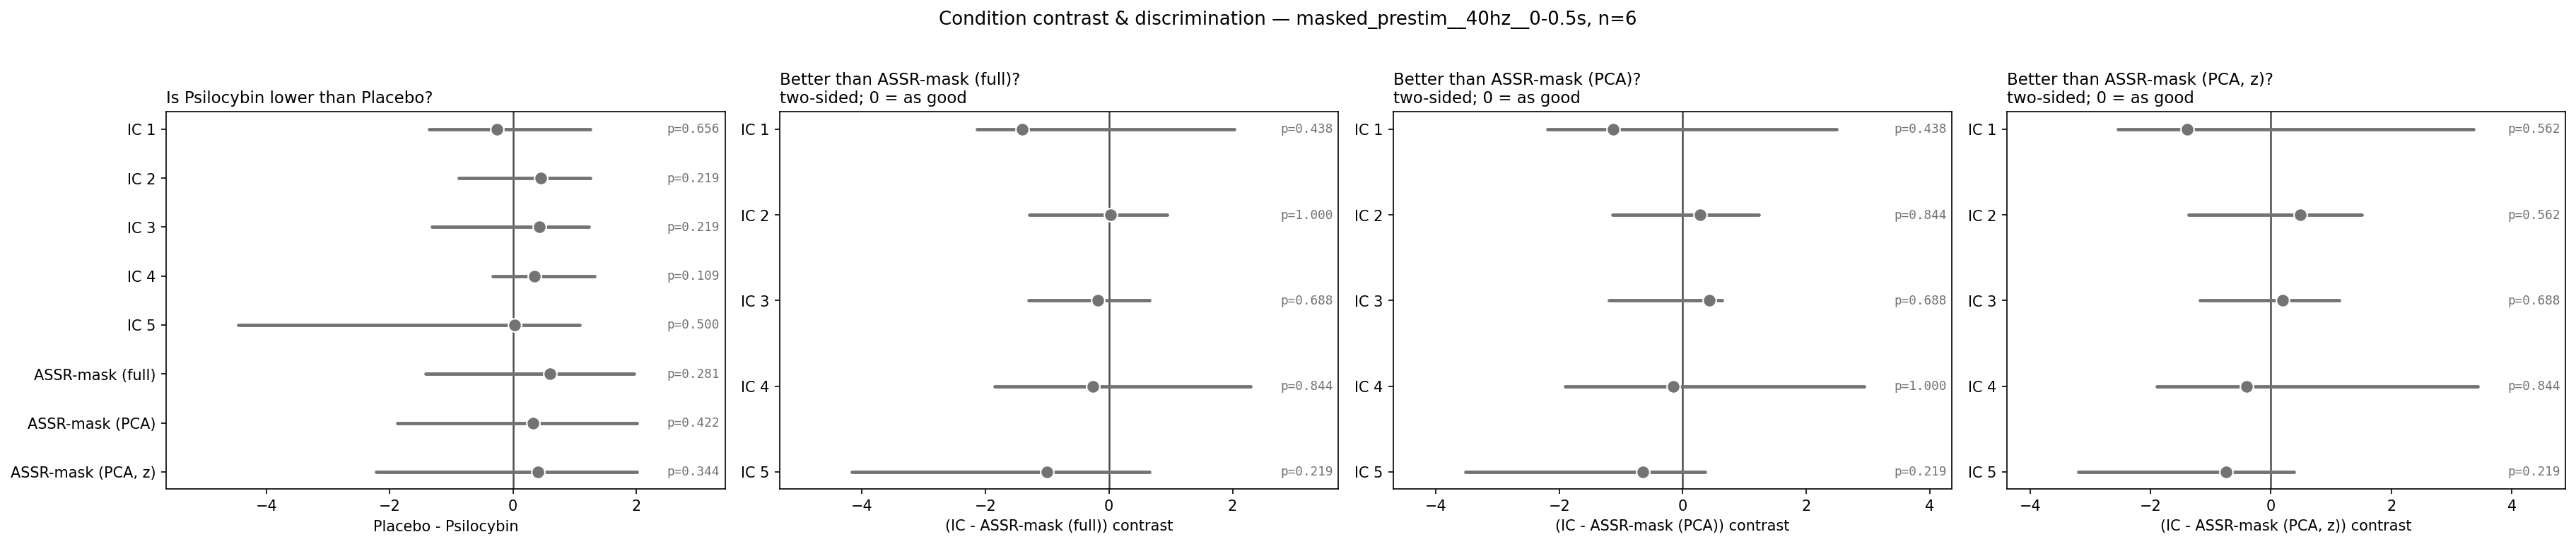

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/40hz/0-0.5s/pvalue_summary__mean_prestim.png**

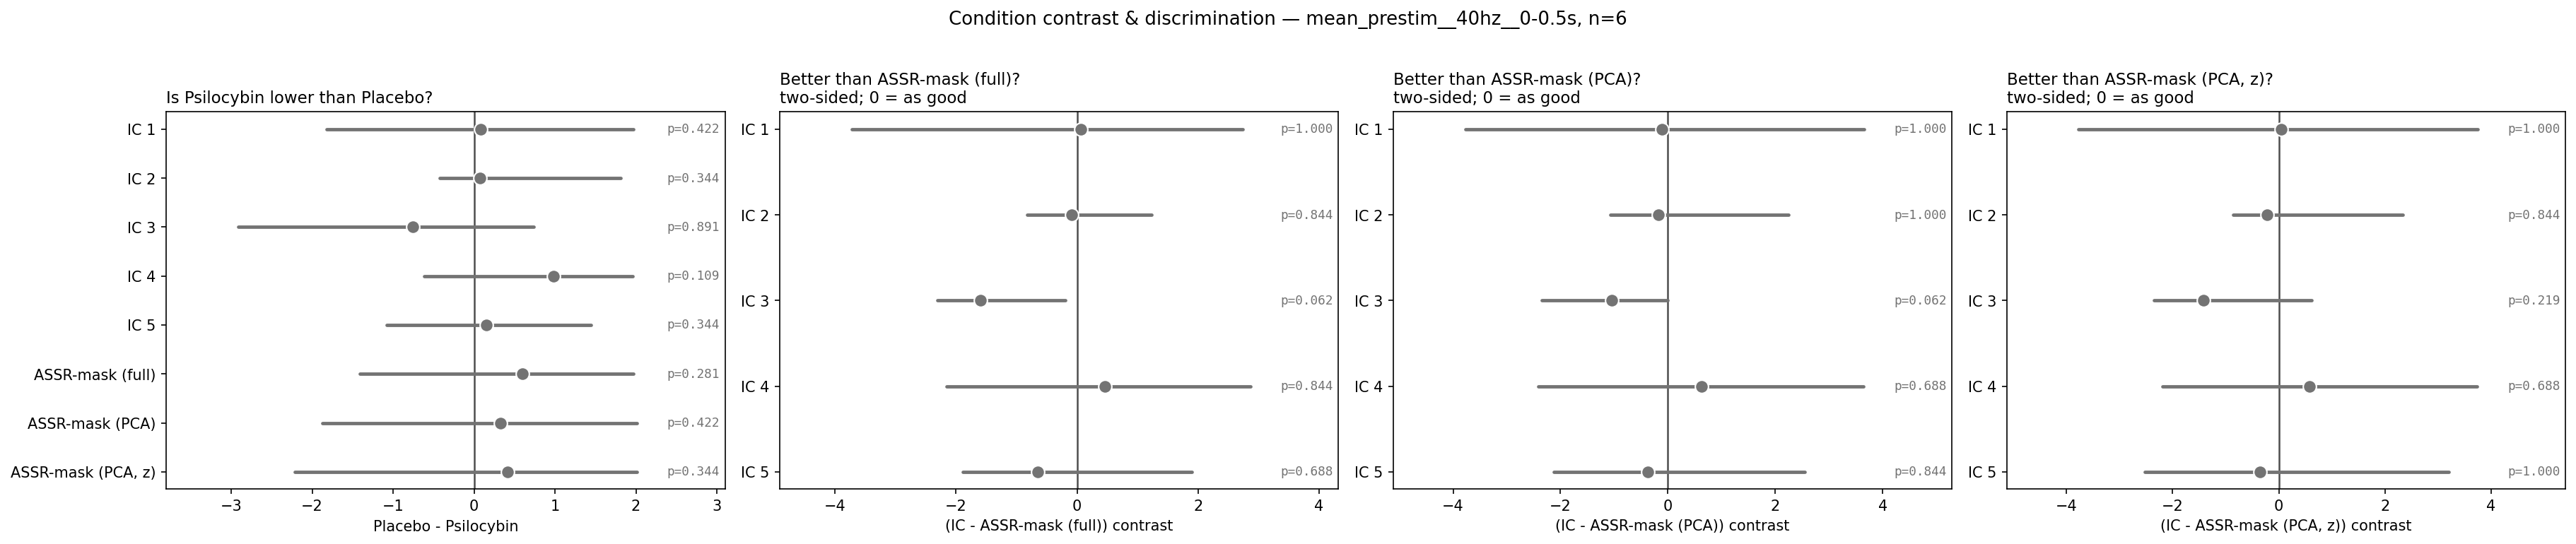

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/40hz/0-0.5s/pvalue_summary__prestim.png**

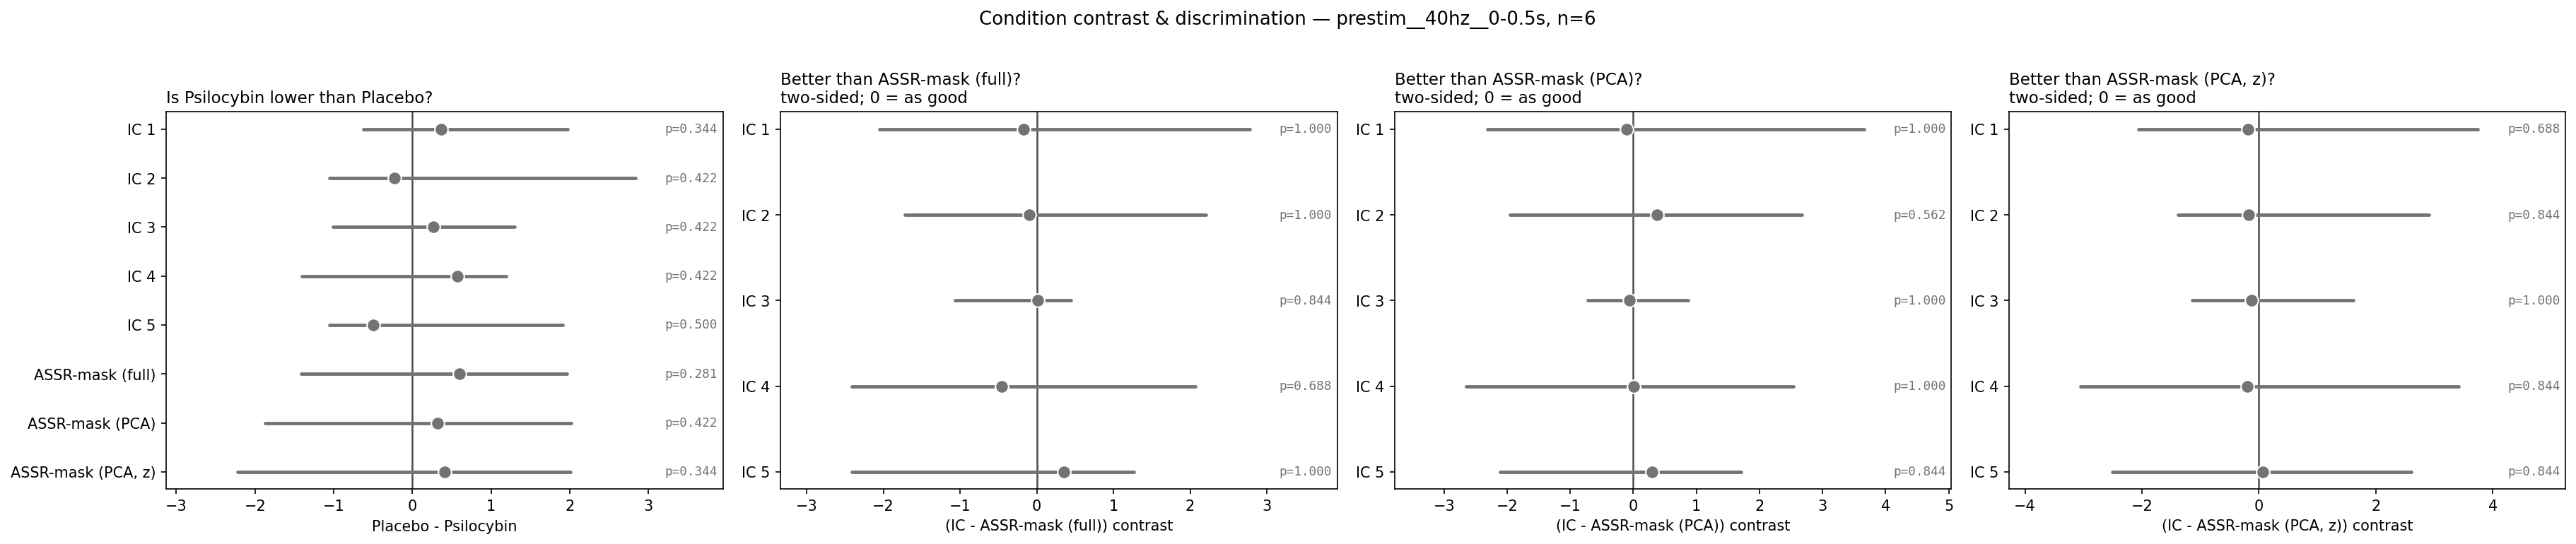

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/40hz/0-0.5s/snr_by_condition__masked_prestim.png**

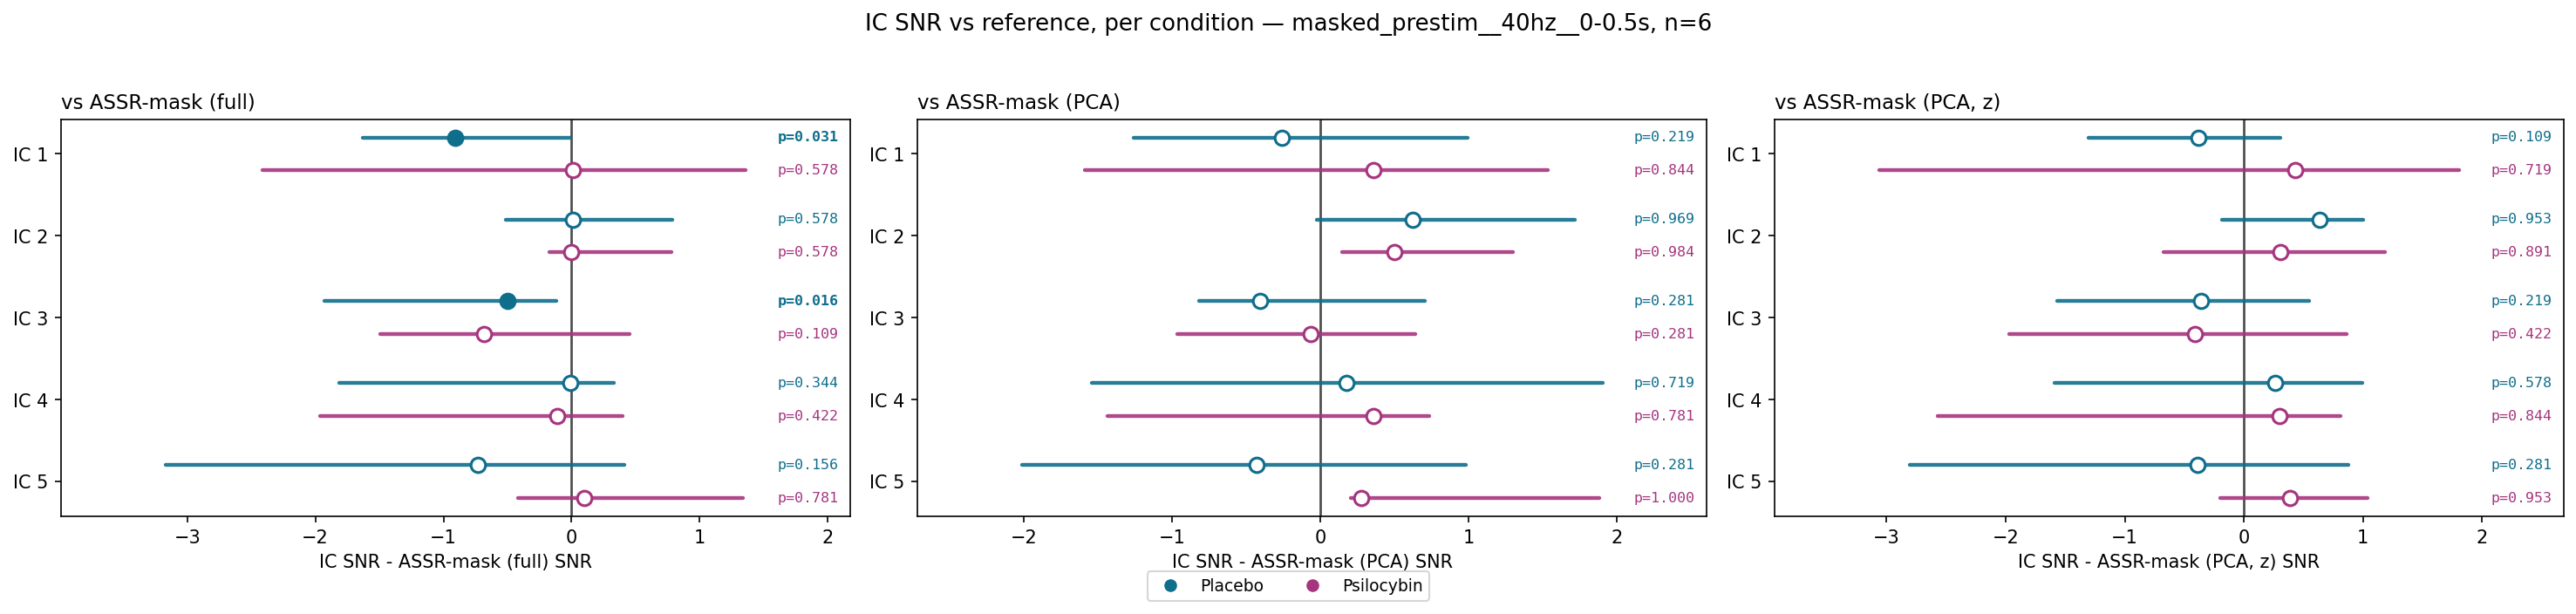

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/40hz/0-0.5s/snr_by_condition__mean_prestim.png**

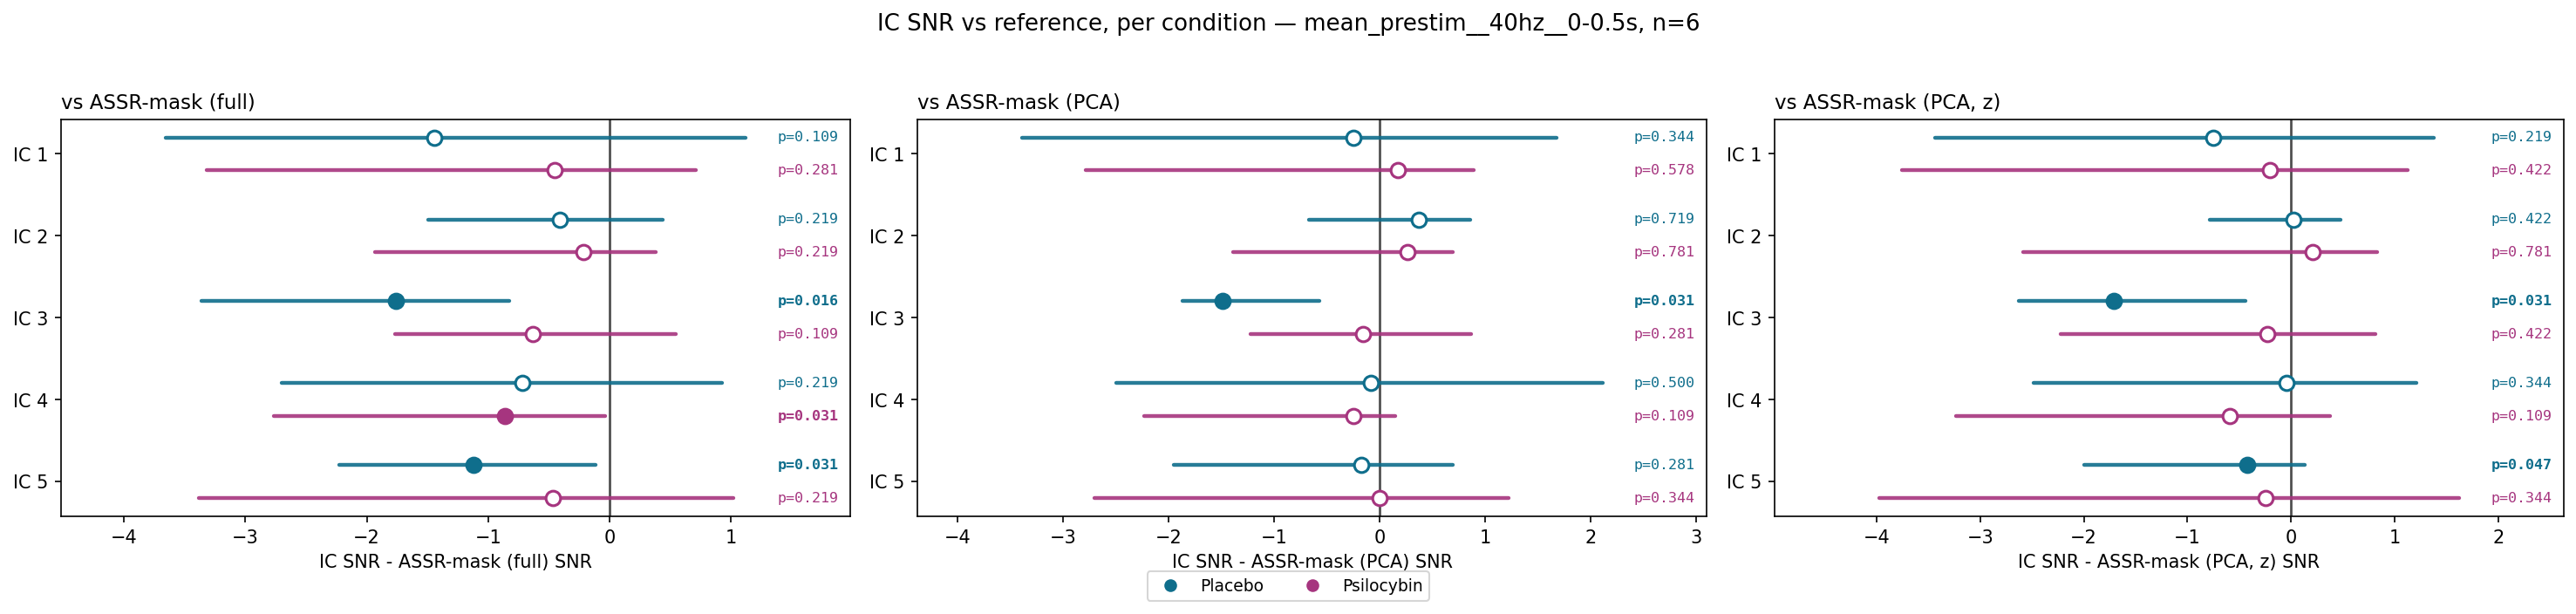

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/40hz/0-0.5s/snr_by_condition__prestim.png**

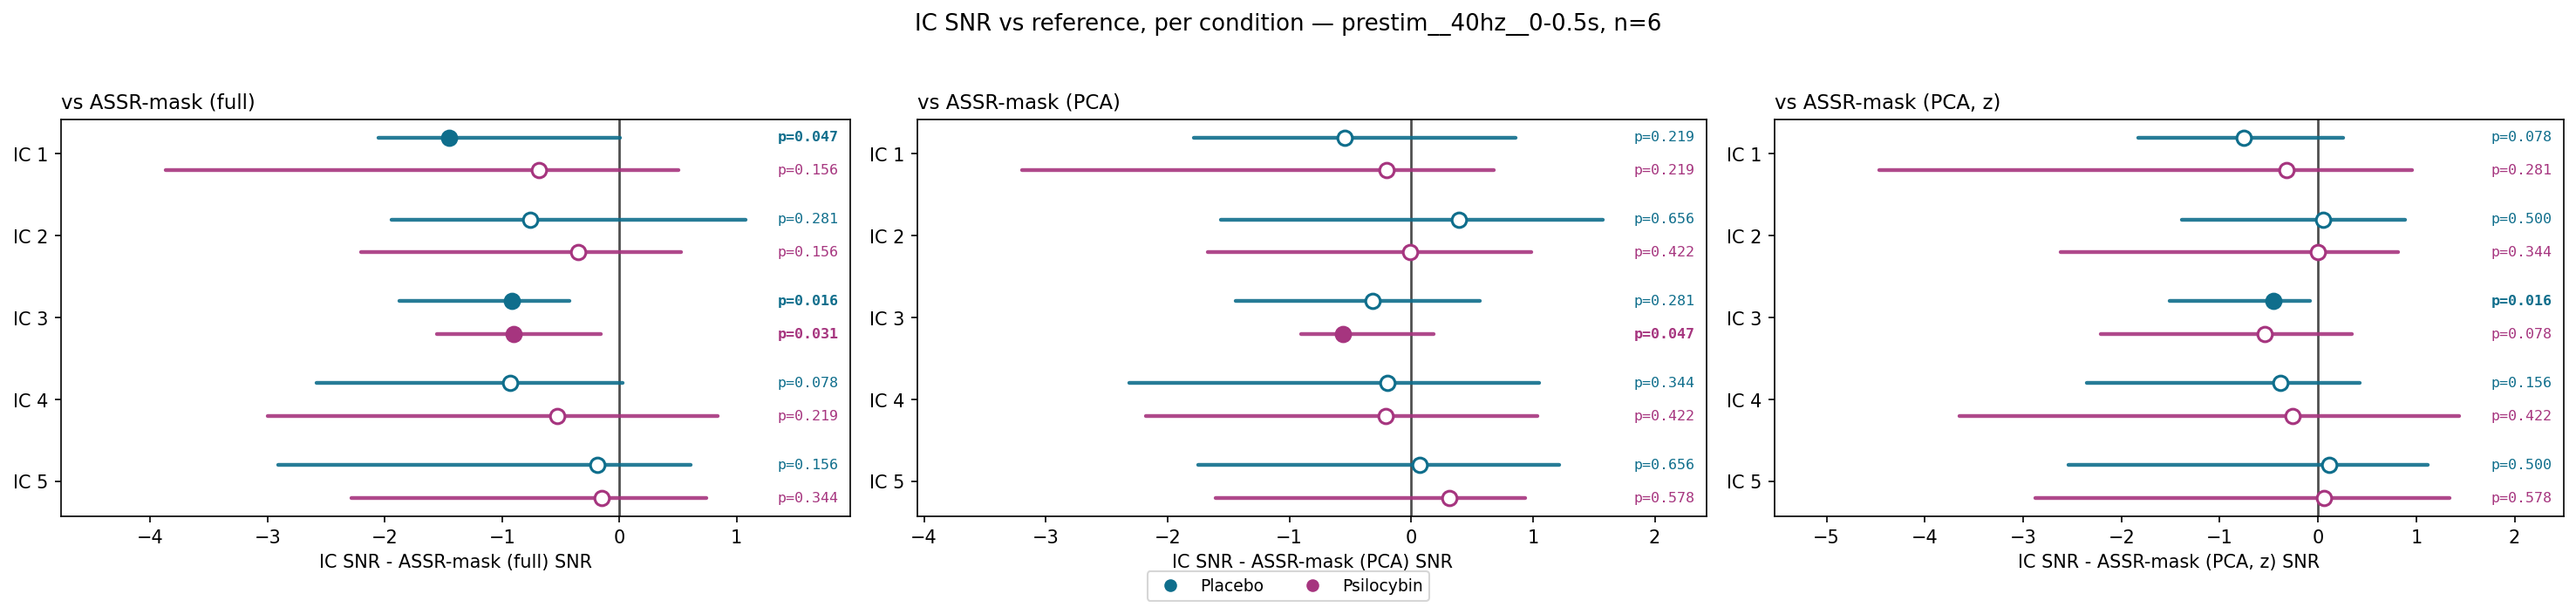

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/40hz/0-0.5s/trial_course_by_source__masked_prestim.png**

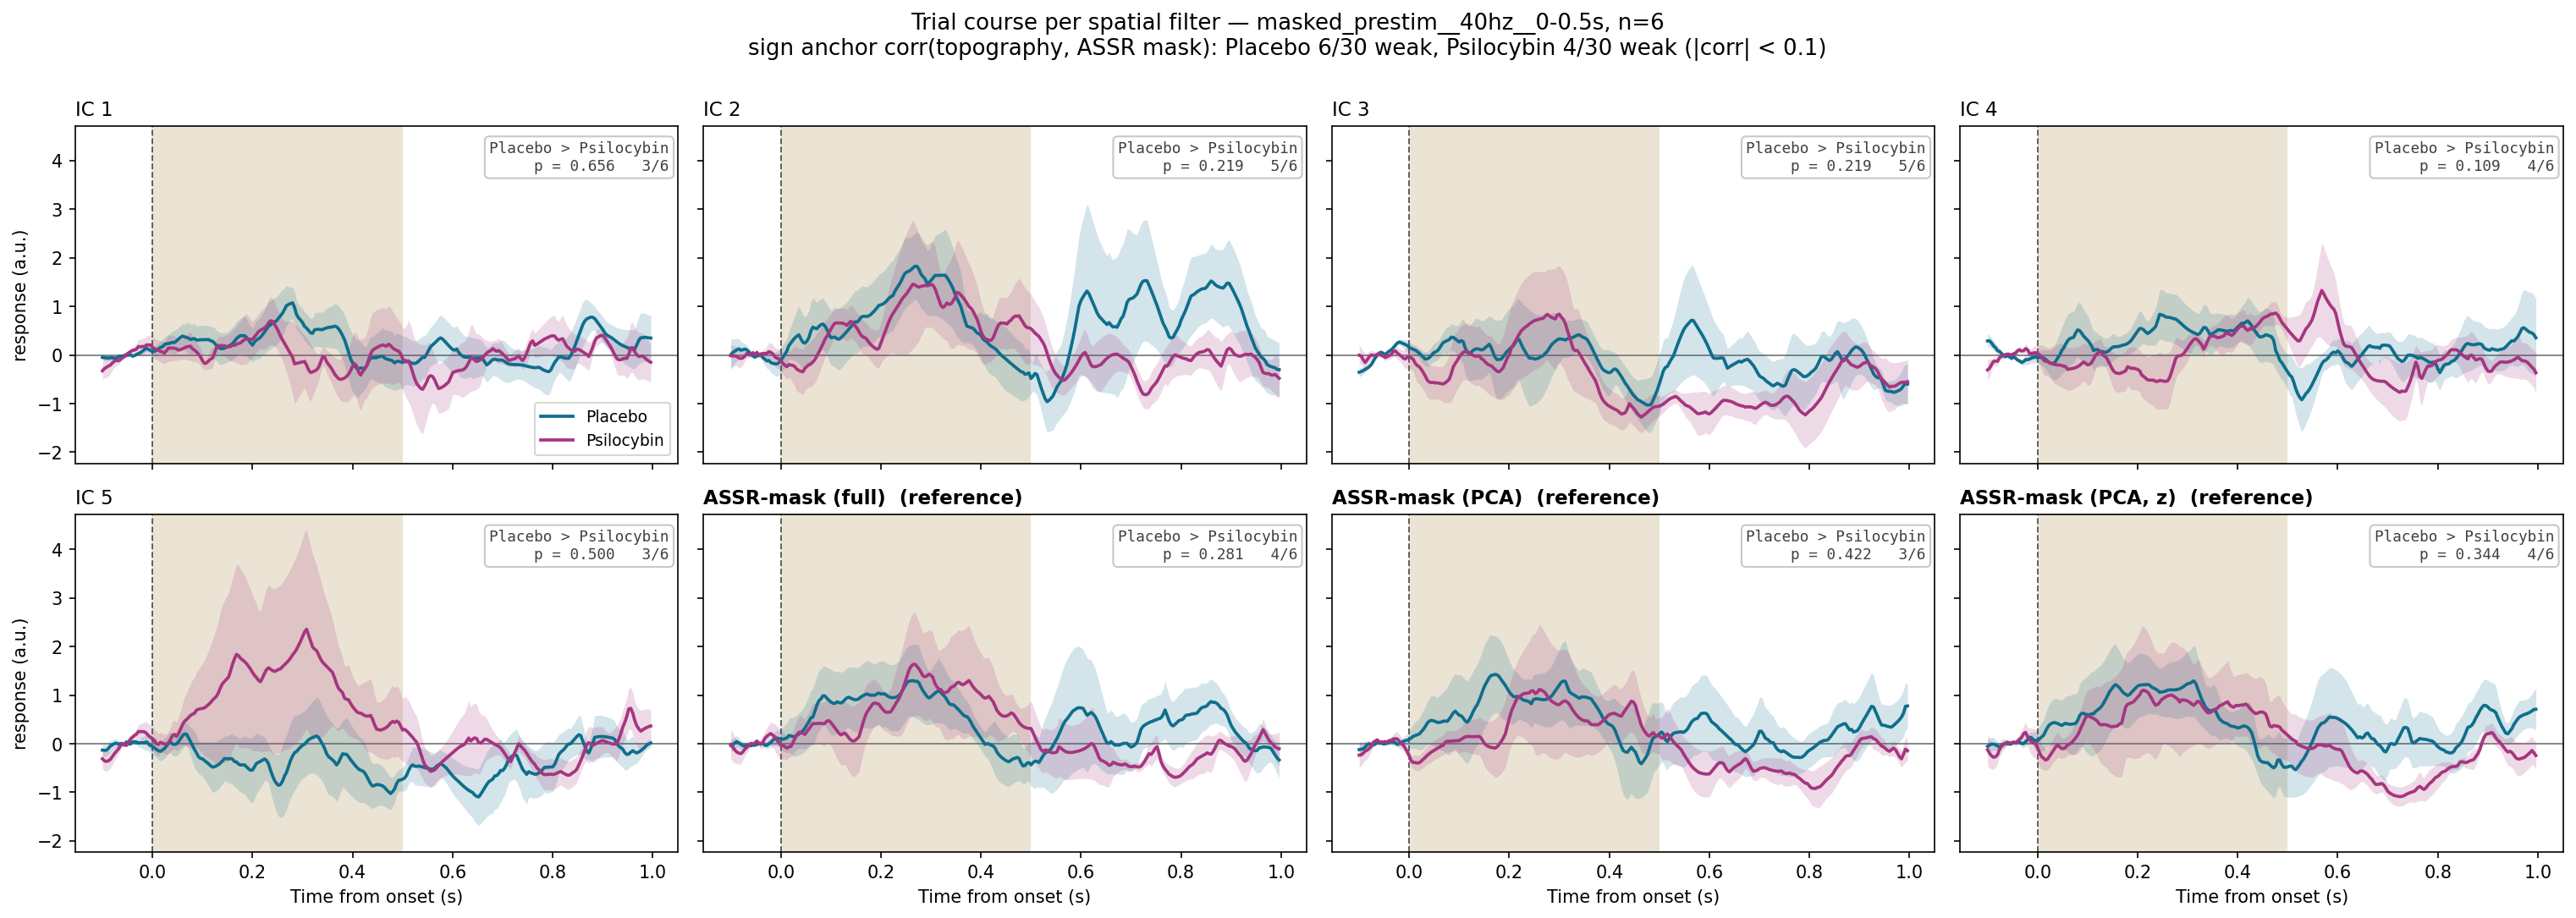

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/40hz/0-0.5s/trial_course_by_source__mean_prestim.png**

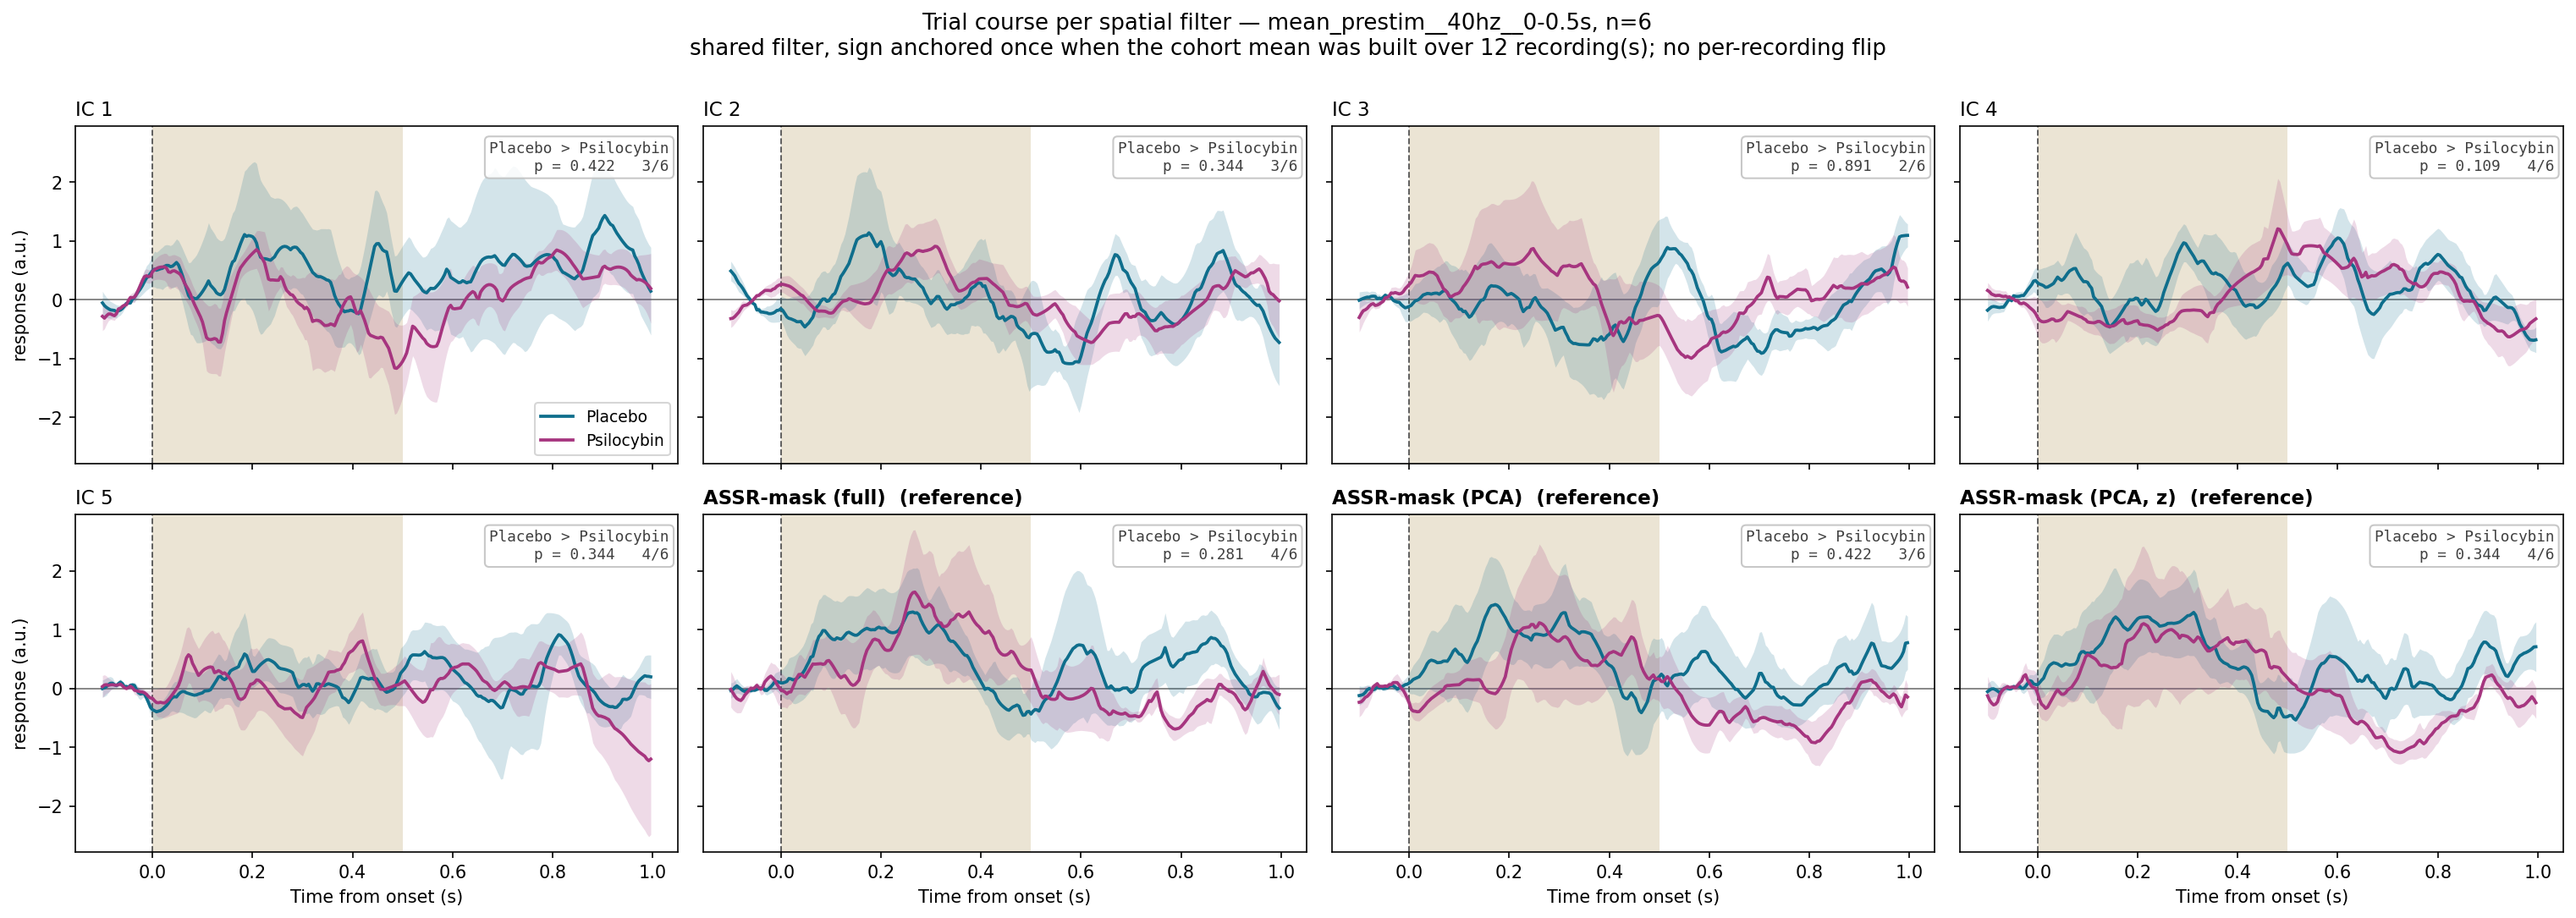

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/40hz/0-0.5s/trial_course_by_source__prestim.png**

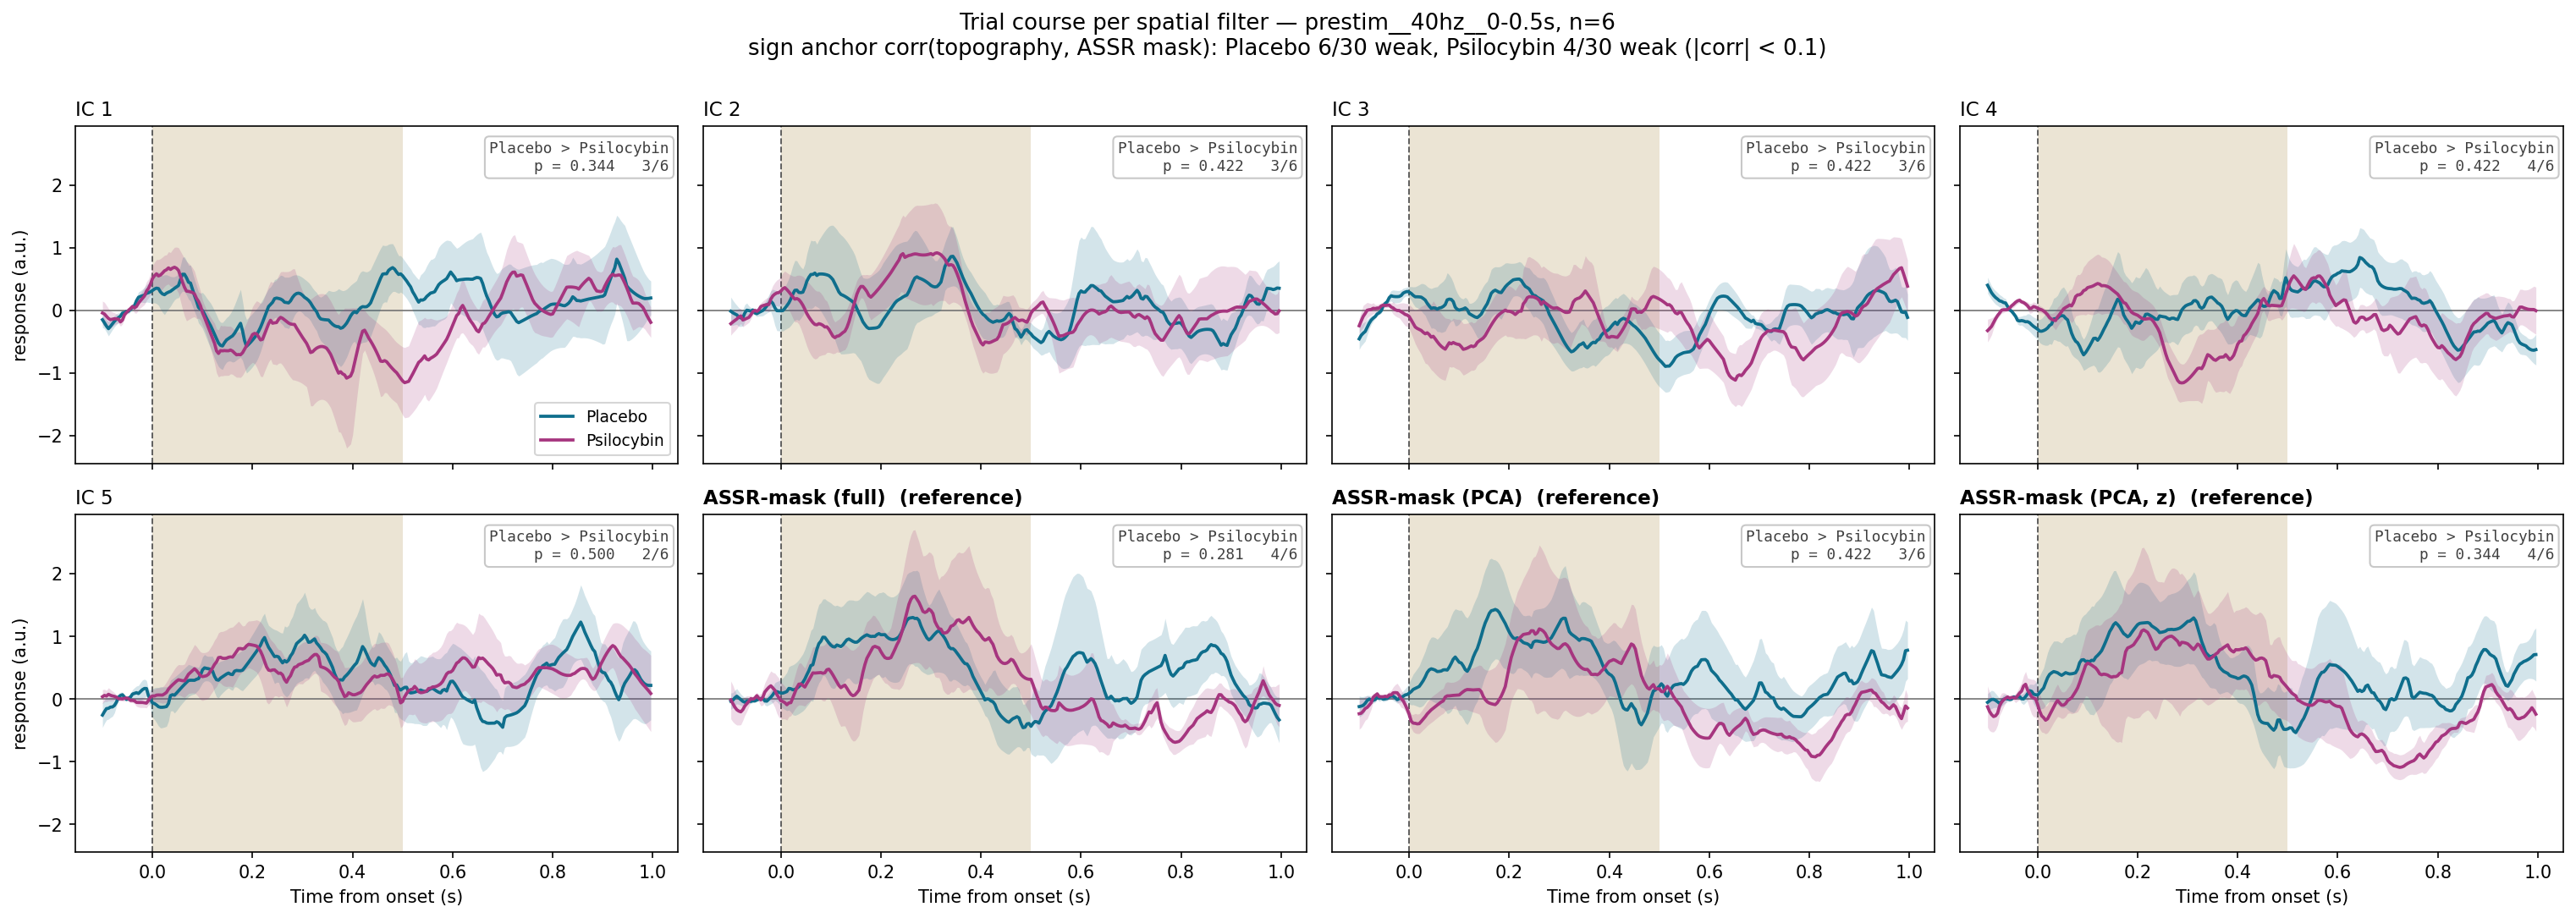

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/mean_filter_topomaps.png**

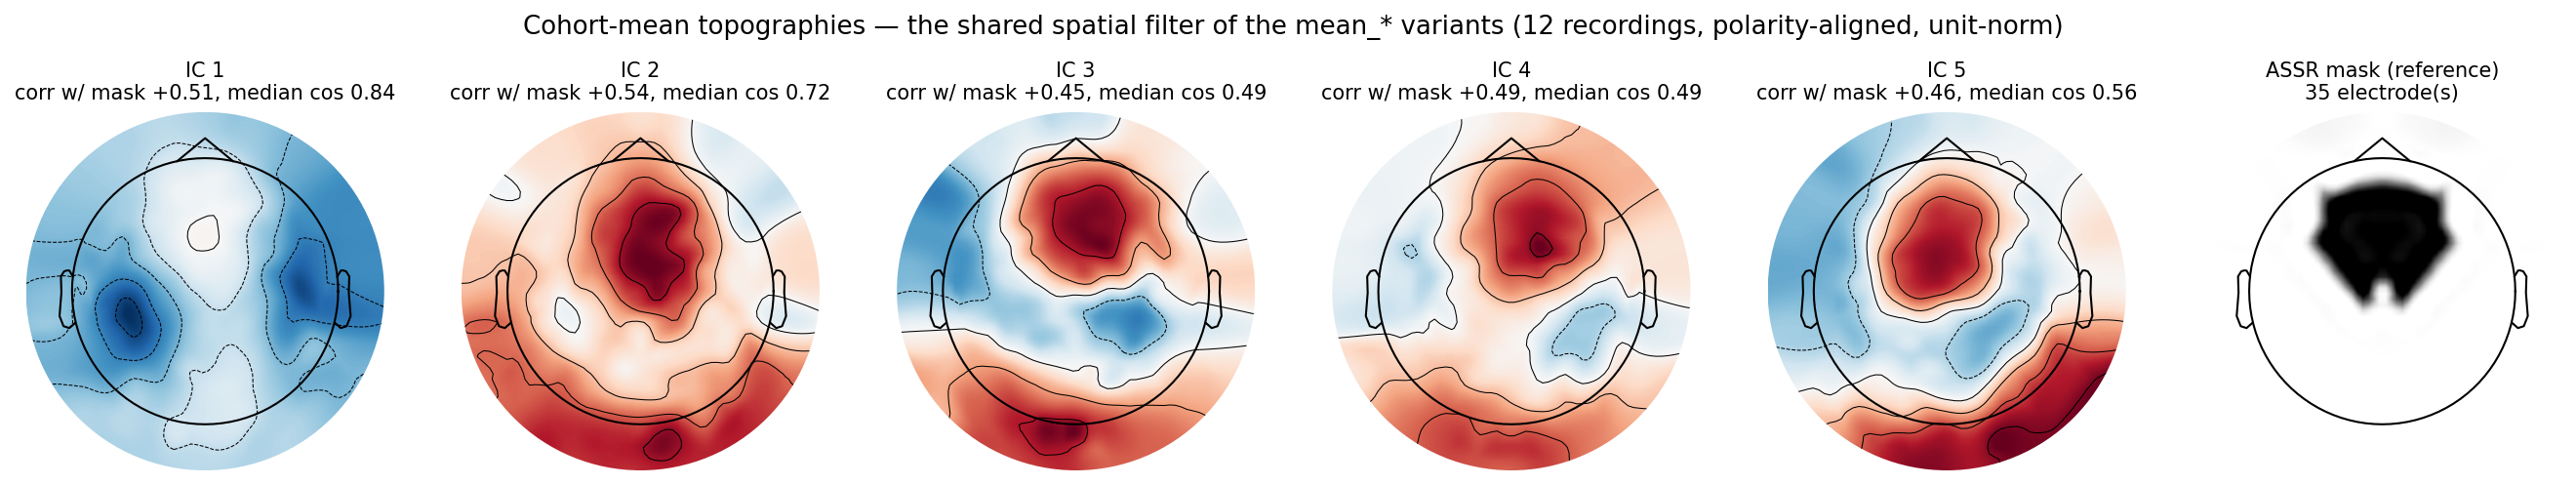

**06-iva-condition-comparison/JoinedSeparate_ASSR/broadband/assr_snr_grid/pca_5/mean_masked_filter_topomaps.png**

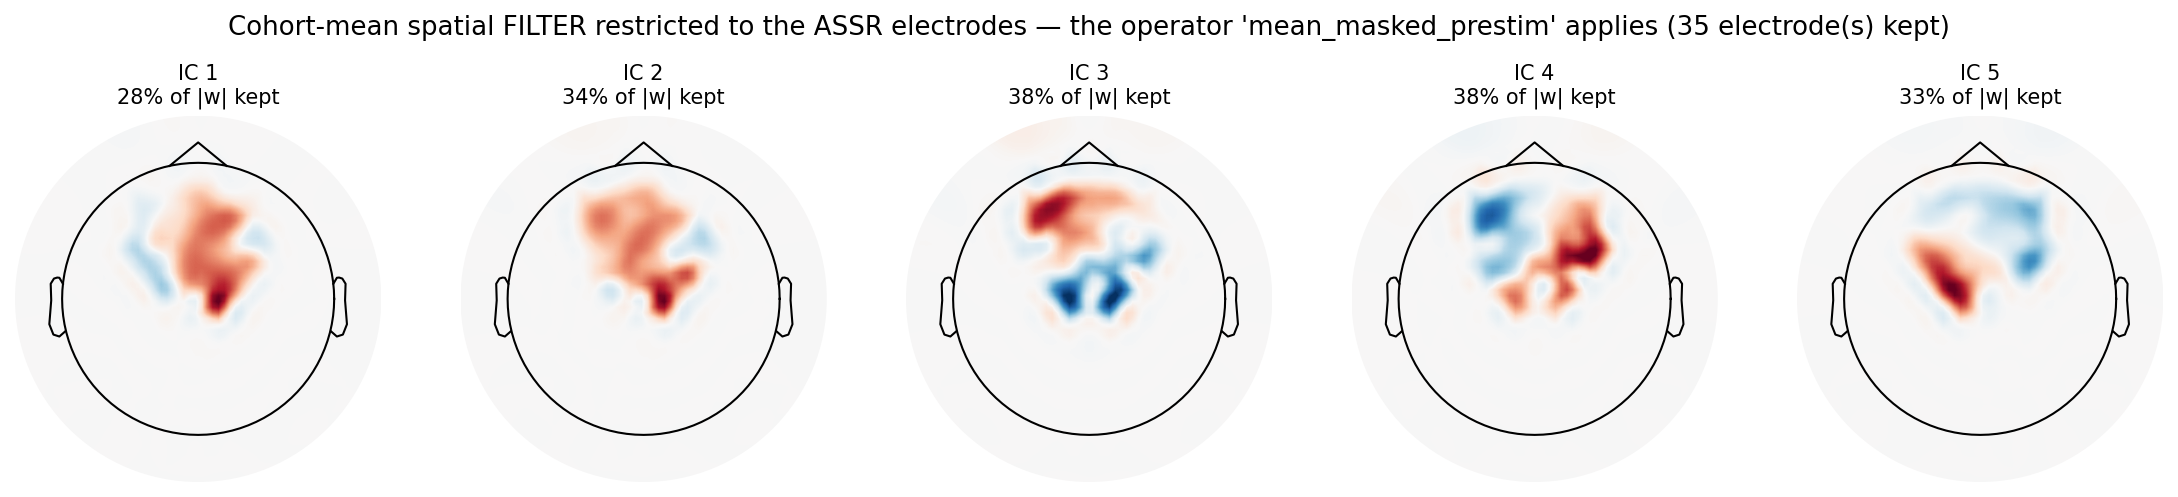

In [8]:
for png in sorted(PLOTS_DIR.rglob("*.png")):
    display(Markdown(f"**{png.relative_to(PLOTS_DIR)}**"))
    display(Image(filename=str(png)))